# Regression

In [1]:
# Numerical arrays.
import numpy as np

# Plots.
import matplotlib.pyplot as plt

# Data frames.
import pandas as pd

# Machine learning models.
import sklearn.linear_model as lm

# Statistical models.
import statsmodels.api as sm

In [2]:
# Plots styles.
plt.style.use('ggplot')

# Plot size.
plt.rcParams['figure.figsize'] = (8, 4)

In [3]:
# Create two points.
x = np.array([4.0, 16.0])
y = np.array([6.0, 12.0])

x, y

(array([ 4., 16.]), array([ 6., 12.]))

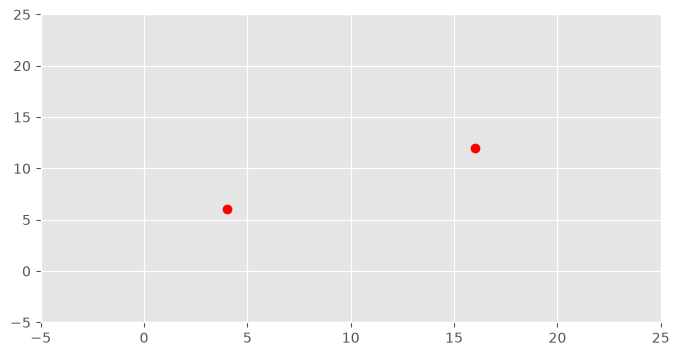

In [4]:
# Plot the points.
plt.plot(x, y, 'ro')

# Give ourselves some space.
plt.xlim([-5.0, 25.0])
plt.ylim([-5.0, 25.0]);

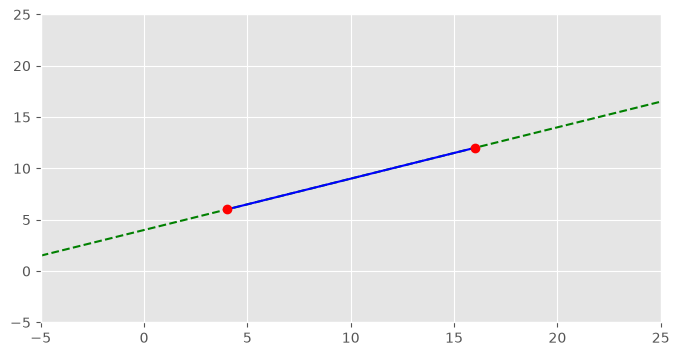

In [5]:
# Plot a straight line.
l = np.linspace(-5.0, 25.0, 100)
plt.plot(l, 0.5 * l + 4.0, 'g--')

# Plot a straight line segment.
l = np.linspace(4.0, 16.0, 10)
plt.plot(l, 0.5 * l + 4.0, 'b-')

# Plot the points.
plt.plot(x, y, 'ro')

# Give ourselves some space.
plt.xlim([-5.0, 25.0])
plt.ylim([-5.0, 25.0]);

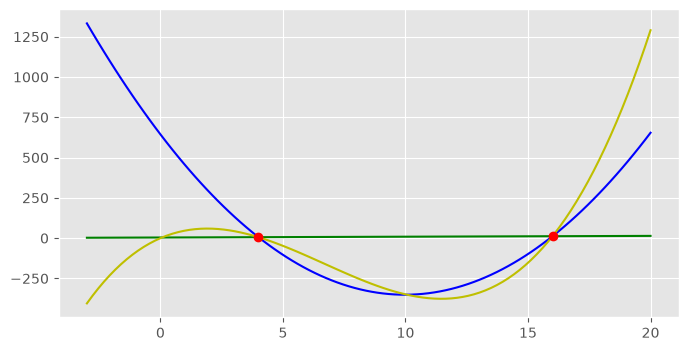

In [6]:
# Plot a straight line.
l = np.linspace(-3.0, 20.0, 100)
plt.plot(l, 0.5 * l + 4.0, 'g-')

# Plot a parabola.
plt.plot(l, 10.0 * (l**2) - 199.5 * l + 644.0, 'b-')

# Plot a cubic.
plt.plot(l, (l**3)  - 20.0625 * l**2  + 65.75 * l, 'y-')

# Plot the points.
plt.plot(x, y, 'ro');

## Lines With No Noise

In [7]:
# Set up some x values.
x = np.linspace(0.0, 10.0, 1001)

x

array([ 0.  ,  0.01,  0.02, ...,  9.98,  9.99, 10.  ], shape=(1001,))

$ y = 5 x + 2 $

In [8]:
# Create y - note numpy's element-wise operations.
y = 5.0 * x + 2.0

In [9]:
# Look at y.
y

array([ 2.  ,  2.05,  2.1 , ..., 51.9 , 51.95, 52.  ], shape=(1001,))

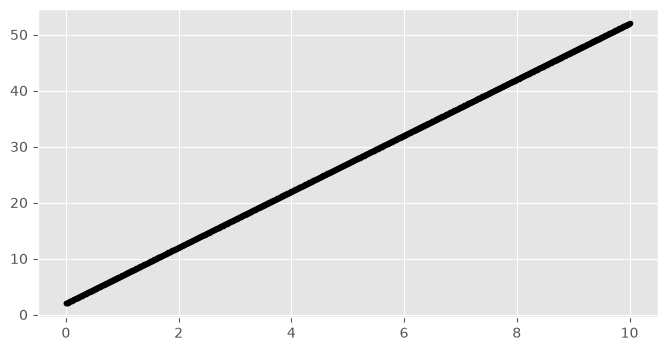

In [10]:
# Plot x versus y.
plt.plot(x, y, 'k.');

In [11]:
# Do regression on the x and y arrays using numpy.
np.polyfit(x, y, 1)

array([5., 2.])

## Lines With Noise

$ y = 3 x - 1 + \epsilon $

In [12]:
# Create a y with noise.
y = 3.0 * x - 1.0 + np.random.normal(0.0, 1.0, len(x))

In [13]:
# Look at y.
y

array([ 0.31983952,  0.26767773, -0.85487964, ..., 29.95539022,
       29.0410146 , 29.79845227], shape=(1001,))

In [14]:
# Do regression on the x and y arrays using numpy.
np.polyfit(x, y, 1)

array([ 2.99441474, -0.99514791])

In [15]:
# Create variables with those values.
m, c = np.polyfit(x, y, 1)

# Have a look at m and c.
m, c

(np.float64(2.9944147389370195), np.float64(-0.9951479107975783))

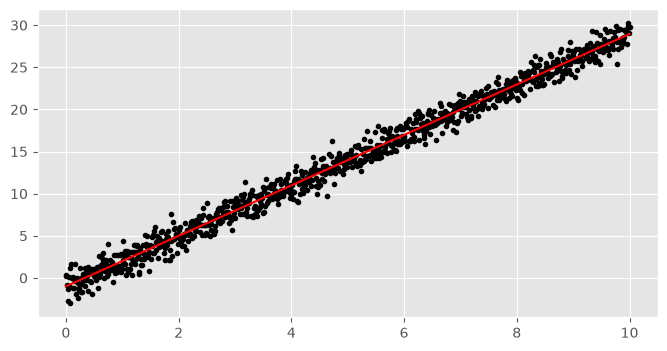

In [16]:
# Plot x and y and the regression line in red.
plt.plot(x, y, 'k.')
plt.plot(x, m * x + c, 'r-');

## Hand Calculated

We can easily calculate the best m and c ourselves.

In [17]:
# Calculate mean x and mean y.
x_avg = np.mean(x)
y_avg = np.mean(y)

# Subtract means from x and y.
x_zero = x - x_avg
y_zero = y - y_avg

# Dot product of mean-adjusted x and y divided by dot product of mean adjusted x with itself.
m = np.sum(x_zero * y_zero) / np.sum(x_zero * x_zero)
# Subtract m times average x from average y.
c = y_avg - m * x_avg

# Let's have a look - same values as above.
m, c

(np.float64(2.99441473893702), np.float64(-0.9951479107975807))

## Higher Dimensions

$ y = 2 x^2 + 5x + 1 + \epsilon $

In [18]:
# Create y from a polynomial in x.
y =  2.0 * x * x + 5.0 * x + 1.0 + np.random.normal(0.0, 1.0, len(x))

In [19]:
# Look at y.
y

array([1.02249530e-01, 2.35808413e+00, 1.12621732e+00, ...,
       2.49445578e+02, 2.49657540e+02, 2.49906881e+02], shape=(1001,))

In [20]:
# Blindly try the regression - we get answers.
# Create variables with those values.
m, c = np.polyfit(x, y, 1)

# Have a look at m and c.
m, c

(np.float64(25.003091169244787), np.float64(-32.311665074929834))

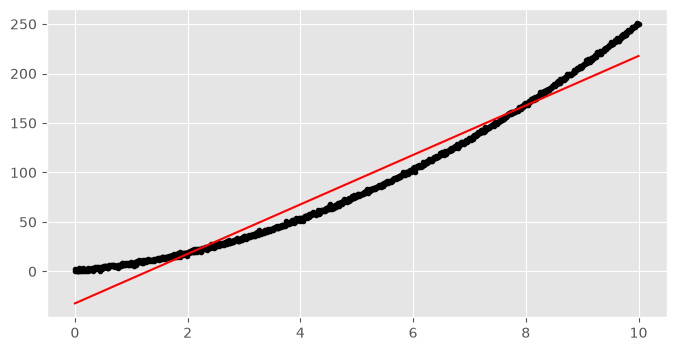

In [21]:
# Plot the line and the points.
plt.plot(x, y, 'k.')

plt.plot(x, m * x + c, 'r-');

Note how the points below the line are bunched in a specific $x$ range.

In [22]:
# Create variables with those values.
a, b, c = np.polyfit(x, y, 2)

a, b, c

(np.float64(1.9940718583823773),
 np.float64(5.062372585421021),
 np.float64(0.8896313671366625))

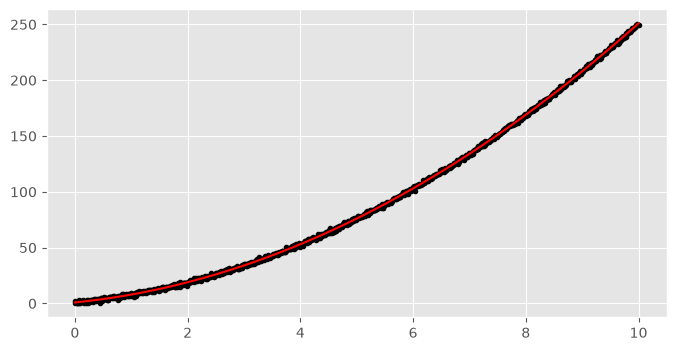

In [23]:
# Plot the line and the points.
plt.plot(x, y, 'k.')
plt.plot(x, a * x * x + b * x + c, 'r-');

## Multiple Linear Regression

Let's try multiple linear regression using sklearn.  
[https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)

In [24]:
# Create a linear regression model instance.
m = lm.LinearRegression()

In [25]:
# Read the iris csv from online.
df = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/refs/heads/master/iris.csv')

In [26]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


$$ petalwidth = t (sepallength) + u (sepalwidth) + v (petallength) + c $$

In [27]:
# Let's pretend we want to do linear regression on these variables to predict petal width.
x = df[['sepal_length', 'sepal_width', 'petal_length']]

In [28]:
# Here's petal width.
y = df['petal_width']

In [29]:
# Ask our model to fit the data.
m.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-0.21, 0.22, 0.52]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['sepal_length','sepal_width','petal_length']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.2403
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [30]:
# Here's our intercept.
m.intercept_

np.float64(-0.24030738911225757)

In [31]:
# Here's our coefficients, in order.
m.coef_

array([-0.20726607,  0.22282854,  0.52408311])

In [32]:
# See how good our fit is.
m.score(x, y)

0.9378502736046809

In [33]:
# Calculating the score by hand.
t, u, v = m.coef_
c = m.intercept_

y_avg = y.mean()

u = ((y - (t * x['sepal_length'] + u * x['sepal_width'] + v * x['petal_length'] + c))**2).sum()
v = ((y - y.mean())**2).sum()

1 - (u/v)

np.float64(0.9378502736046809)

## Using statsmodels

In [34]:
# Tell statmodels to include an intercept.
xwithc = sm.add_constant(x)

# Create a model.
msm = sm.OLS(y, xwithc)

# Fit the data.
rsm = msm.fit()

# Print a summary.
print(rsm.summary())

                            OLS Regression Results                            
Dep. Variable:            petal_width   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     734.4
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           7.83e-88
Time:                        13:30:22   Log-Likelihood:                 36.751
No. Observations:                 150   AIC:                            -65.50
Df Residuals:                     146   BIC:                            -53.46
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.2403      0.178     -1.347   

## End